DataFrame head after setting date as index:
            nivel_lago  caudal_salida  precipitacion  temperatura  \
fecha                                                               
2012-01-01      51.780          292.0       2.754378        4.142   
2012-01-02      51.733          285.0       2.264622        4.150   
2012-01-03      51.809          294.0       1.616913        4.317   
2012-01-04      52.010          328.0      13.679318        4.492   
2012-01-05      52.430          393.0       0.014222        4.817   

            evapotranspiracion  
fecha                           
2012-01-01               2.604  
2012-01-02               2.309  
2012-01-03               2.829  
2012-01-04               3.024  
2012-01-05               2.438  

DataFrame info after setting date as index:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3042 entries, 2012-01-01 to 2020-04-29
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------            

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_15 (GRU)                    │ (None, 30, 128)        │        51,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_16 (GRU)                    │ (None, 30, 64)         │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_17 (GRU)                    │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 98,529 (384.88 KB)

 Trainable params: 98,529 (384.88 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 19s 132ms/step - loss: 0.0110 - mae: 0.0732 - val_loss: 0.0038 - val_mae: 0.0387 - learning_rate: 0.0010
Epoch 2/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 9s 122ms/step - loss: 0.0037 - mae: 0.0400 - val_loss: 0.0028 - val_mae: 0.0397 - learning_rate: 0.0010
Epoch 3/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 9s 118ms/step - loss: 0.0029 - mae: 0.0371 - val_loss: 0.0018 - val_mae: 0.0279 - learning_rate: 0.0010
Epoch 4/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 9s 105ms/step - loss: 0.0022 - mae: 0.0321 - val_loss: 0.0015 - val_mae: 0.0247 - learning_rate: 0.0010
Epoch 5/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - loss: 0.0020 - mae: 0.0305 - val_loss: 0.0012 - val_mae: 0.0254 - learning_rate: 0.0010
Epoch 6/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 9s 119ms/step - loss: 0.0019 - mae: 0.0304 - val_loss: 0.0012 - val_mae: 0.0258 - learning_rate: 0.0010
Epoch 7/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 9s 112ms/step - loss: 0.0022 - mae: 0.0324 - val_loss: 7.3315e-04 - val_mae: 0.0172 - learning_r

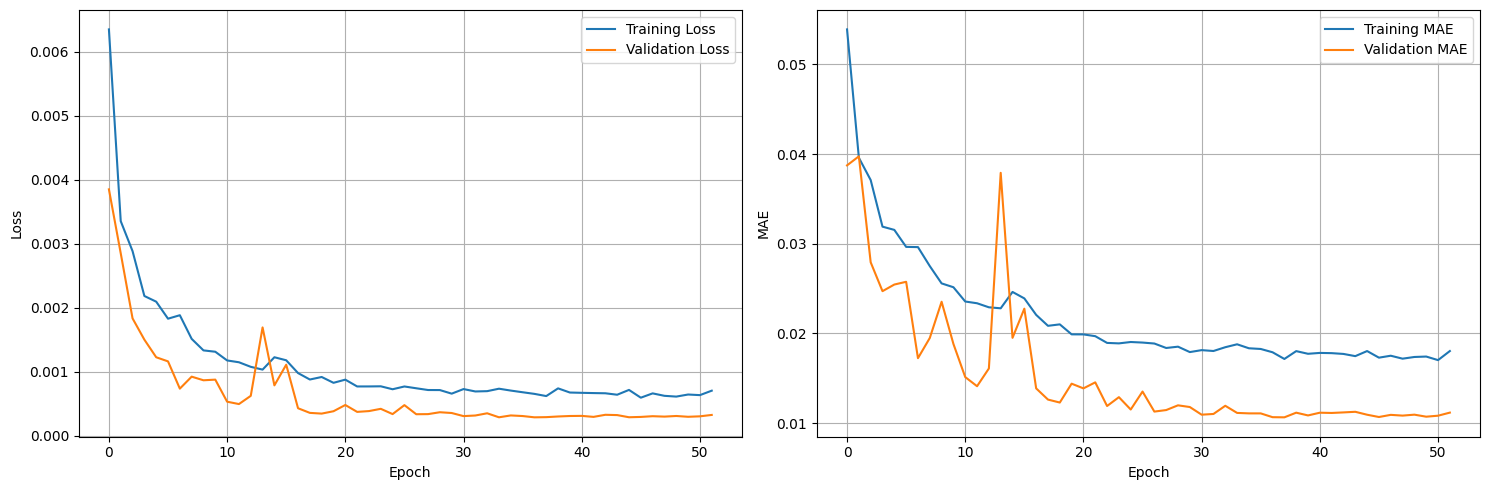

19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step
Shape of original y_test: (603,)
Shape of y_pred: (603,)
Shape of y_test_actual: (603,)
RMSE: 0.0635
MAE: 0.0401
RSR: 0.1055
MAPE: 0.08%

Simple GRU results saved: RMSE=0.0635, MAE=0.0401, RSR=0.1055, MAPE=0.08%


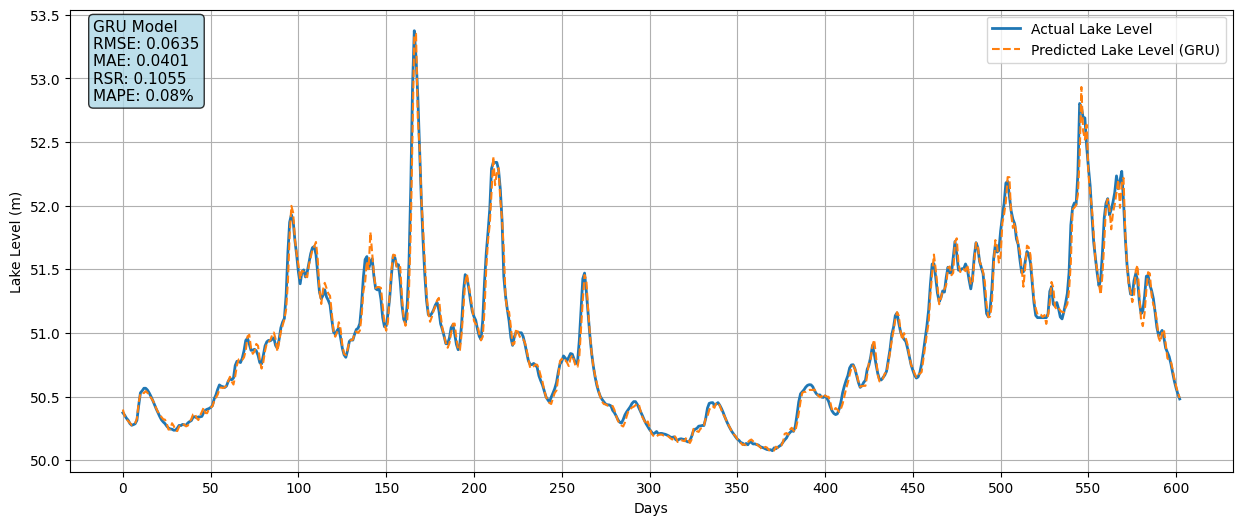

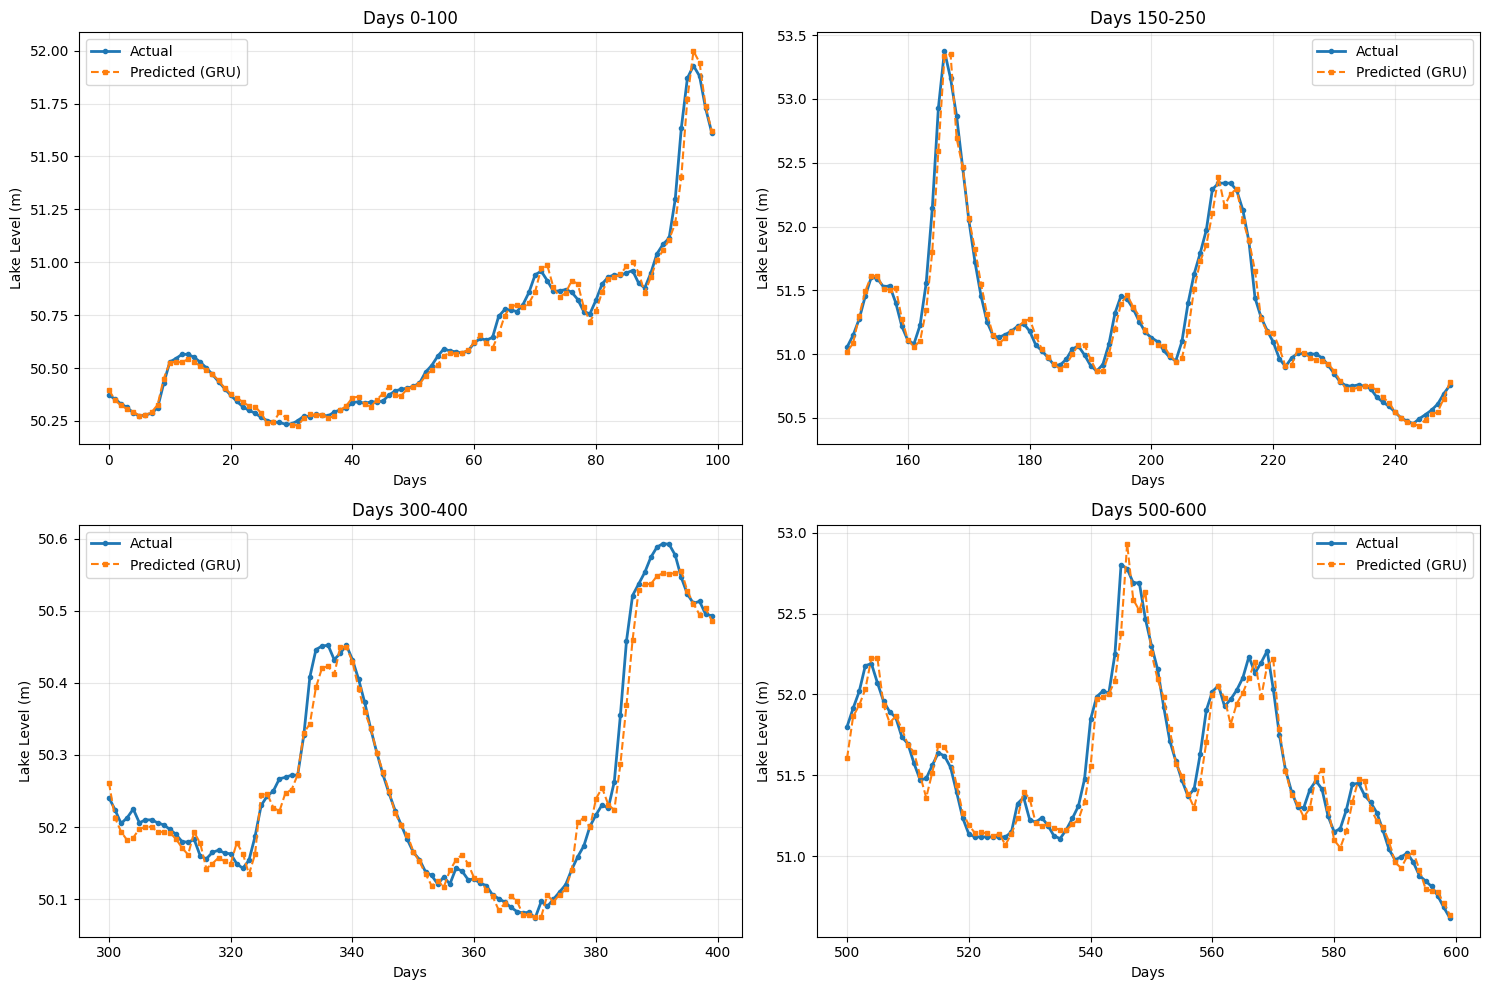

In [ ]:
#SIMPLE GRU
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Load and preprocess data
df = pd.read_csv('DATOS.csv')

df['fecha'] = pd.to_datetime(df['fecha'], format='%d/%m/%Y')
df.set_index('fecha', inplace=True)

print("DataFrame head after setting date as index:")
print(df.head())
print("\nDataFrame info after setting date as index:")
df.info()

df.interpolate(method='linear', inplace=True)

print("DataFrame head after interpolation:")
print(df.head())
print("\nDataFrame info after interpolation:")
df.info()

# Initialize MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))

# Select all columns for scaling
features_to_scale = df.columns

# Apply scaling
df_scaled_array = scaler.fit_transform(df[features_to_scale])

# Convert the scaled array back to a DataFrame
df_scaled = pd.DataFrame(df_scaled_array, columns=features_to_scale, index=df.index)

print("First 5 rows of the scaled DataFrame (df_scaled):")
print(df_scaled.head())

print("\nDataFrame info after scaling:")
df_scaled.info()

# 1. Define the look_back period
look_back = 30

# 2. Define the index of the target column ('nivel_lago')
target_column_index = df_scaled.columns.get_loc('nivel_lago')

# 3. Implement a function to generate sequences
def create_sequences(data, look_back, target_index):
    X, y = [], []
    for i in range(look_back, len(data)):
        X.append(data.iloc[i-look_back : i].values) # Input features for the last 'look_back' days
        y.append(data.iloc[i, target_index])       # Target value for the current day
    return np.array(X), np.array(y)

# Generate sequences
X_data, y_data = create_sequences(df_scaled, look_back, target_column_index)

# 4. Split the arrays into training and test sets (80% train, 20% test chronologically)
train_size = int(len(X_data) * 0.8)

X_train, y_train = X_data[:train_size], y_data[:train_size]
X_test, y_test = X_data[train_size:], y_data[train_size:]

print(f"Shape of X_data: {X_data.shape}")
print(f"Shape of y_data: {y_data.shape}")
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

# Define the GRU model architecture with optimized parameters
model = Sequential()

# Add an Input layer
model.add(Input(shape=(X_train.shape[1], X_train.shape[2])))

# First GRU layer with more units for better learning capacity
model.add(GRU(units=128, return_sequences=True, recurrent_dropout=0.1))
model.add(Dropout(0.3))

# Second GRU layer
model.add(GRU(units=64, return_sequences=True, recurrent_dropout=0.1))
model.add(Dropout(0.3))

# Third GRU layer (no return_sequences as it's the last GRU layer)
model.add(GRU(units=32))
model.add(Dropout(0.2))

# Output layer
model.add(Dense(units=1))

# Compile the model with optimized Adam optimizer
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae'])

# Print model summary
print(model.summary())

# Define callbacks for better training
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

# Train the model with callbacks
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("GRU model training complete.")

# Plot training history
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# COMBINED GRAPH WITH METRICS
# Make predictions with the trained model
y_pred_scaled = model.predict(X_test)

# Reshape y_test for inverse transformation
y_test_reshaped = y_test.reshape(-1, 1)

# Create dummy arrays for inverse transformation
dummy_y_pred = np.zeros((len(y_pred_scaled), df_scaled.shape[1]))
dummy_y_test = np.zeros((len(y_test_reshaped), df_scaled.shape[1]))

# Place the scaled predictions and actual values into the correct column
dummy_y_pred[:, target_column_index] = y_pred_scaled[:, 0]
dummy_y_test[:, target_column_index] = y_test_reshaped[:, 0]

# Inverse transform the predictions and actual values to their original scale
y_pred = scaler.inverse_transform(dummy_y_pred)[:, target_column_index]
y_test_actual = scaler.inverse_transform(dummy_y_test)[:, target_column_index]

print(f"Shape of original y_test: {y_test.shape}")
print(f"Shape of y_pred: {y_pred.shape}")
print(f"Shape of y_test_actual: {y_test_actual.shape}")

# Calculate MAPE
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Avoid division by zero
    non_zero_indices = y_true != 0
    return np.mean(np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])) * 100

# Calculate metrics
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred))
mae = mean_absolute_error(y_test_actual, y_pred)
std_dev_y_test_actual = np.std(y_test_actual)
rsr = rmse / std_dev_y_test_actual
mape = mean_absolute_percentage_error(y_test_actual, y_pred)

print(f'RMSE: {rmse:.4f}')
print(f'MAE: {mae:.4f}')
print(f'RSR: {rsr:.4f}')
print(f'MAPE: {mape:.2f}%')

# Save Simple GRU results
simple_gru_results = {
    'RMSE': rmse,
    'MAE': mae,
    'RSR': rsr,
    'MAPE': mape
}
print(f"\nSimple GRU results saved: RMSE={rmse:.4f}, MAE={mae:.4f}, RSR={rsr:.4f}, MAPE={mape:.2f}%")

# Plotting the results
plt.figure(figsize=(15, 6))
plt.plot(y_test_actual, label='Actual Lake Level', linewidth=2)
plt.plot(y_pred, label='Predicted Lake Level (GRU)', linestyle='--')

plt.xlabel('Days')
plt.ylabel('Lake Level (m)')

# Set x-ticks to skip in groups of 50
max_x_value = len(y_test_actual)
plt.xticks(np.arange(0, max_x_value, 50))

# Add metrics box
metrics_text = f'GRU Model\nRMSE: {rmse:.4f}\nMAE: {mae:.4f}\nRSR: {rsr:.4f}\nMAPE: {mape:.2f}%'
plt.text(0.02, 0.98, metrics_text,
         transform=plt.gca().transAxes,
         fontsize=11,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))

plt.legend()
plt.grid(True)
plt.show()

# Create multiple zoomed sections
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Define different zoom ranges
zoom_ranges = [(0, 100), (150, 250), (300, 400), (500, 600)]

for idx, (start, end) in enumerate(zoom_ranges):
    ax = axes[idx // 2, idx % 2]

    ax.plot(range(start, end),
            y_test_actual[start:end],
            label='Actual',
            linewidth=2,
            marker='o',
            markersize=3)
    ax.plot(range(start, end),
            y_pred[start:end],
            label='Predicted (GRU)',
            linestyle='--',
            marker='s',
            markersize=3)

    ax.set_title(f'Days {start}-{end}')
    ax.set_xlabel('Days')
    ax.set_ylabel('Lake Level (m)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

DataFrame head after setting date as index:
            nivel_lago  caudal_salida  precipitacion  temperatura  \
fecha                                                               
2012-01-01      51.780          292.0       2.754378        4.142   
2012-01-02      51.733          285.0       2.264622        4.150   
2012-01-03      51.809          294.0       1.616913        4.317   
2012-01-04      52.010          328.0      13.679318        4.492   
2012-01-05      52.430          393.0       0.014222        4.817   

            evapotranspiracion  
fecha                           
2012-01-01               2.604  
2012-01-02               2.309  
2012-01-03               2.829  
2012-01-04               3.024  
2012-01-05               2.438  

DataFrame info after setting date as index:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3042 entries, 2012-01-01 to 2020-04-29
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------            

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_15                │ (None, 30, 256)        │       103,680 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_16                │ (None, 30, 128)        │       123,648 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_17                │ (None, 64)             │        31,104 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 258,497 (1009.75 KB)

 Trainable params: 258,497 (1009.75 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 36s 263ms/step - loss: 0.0225 - mae: 0.1036 - val_loss: 0.0030 - val_mae: 0.0347 - learning_rate: 0.0010
Epoch 2/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 19s 249ms/step - loss: 0.0029 - mae: 0.0375 - val_loss: 0.0022 - val_mae: 0.0311 - learning_rate: 0.0010
Epoch 3/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 20s 242ms/step - loss: 0.0022 - mae: 0.0335 - val_loss: 0.0017 - val_mae: 0.0274 - learning_rate: 0.0010
Epoch 4/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 20s 233ms/step - loss: 0.0020 - mae: 0.0320 - val_loss: 0.0015 - val_mae: 0.0260 - learning_rate: 0.0010
Epoch 5/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 18s 241ms/step - loss: 0.0019 - mae: 0.0309 - val_loss: 0.0013 - val_mae: 0.0226 - learning_rate: 0.0010
Epoch 6/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 20s 240ms/step - loss: 0.0017 - mae: 0.0303 - val_loss: 0.0010 - val_mae: 0.0210 - learning_rate: 0.0010
Epoch 7/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 19s 251ms/step - loss: 0.0021 - mae: 0.0322 - val_loss: 0.0010 - val_mae: 0.0207 - learning_

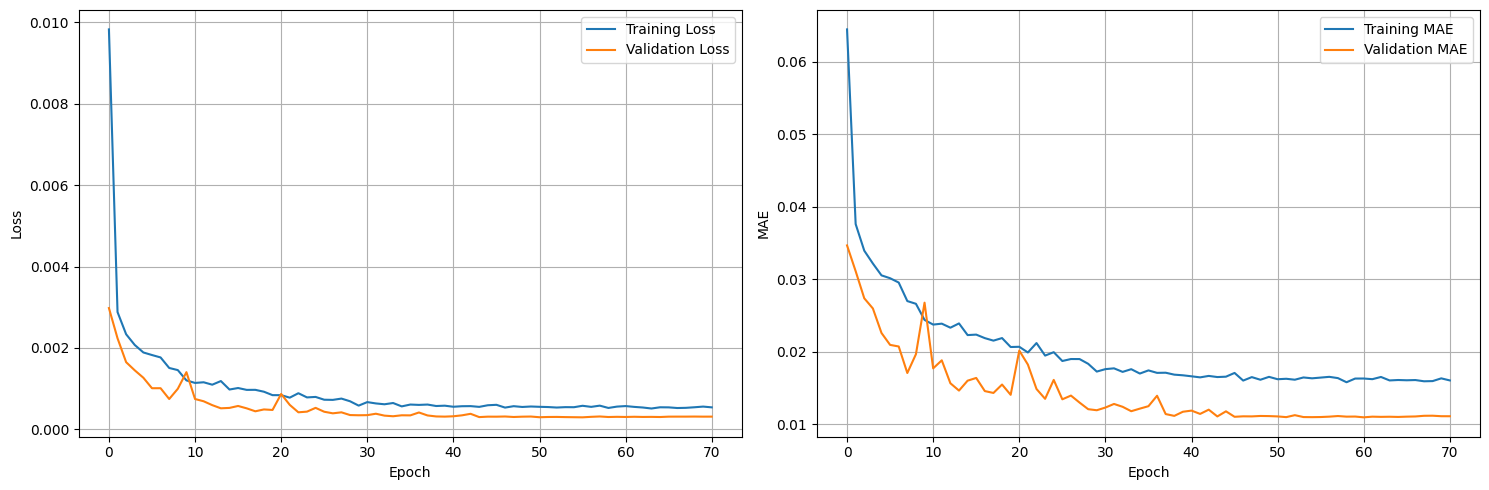

19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 162ms/step
Shape of original y_test: (603,)
Shape of y_pred: (603,)
Shape of y_test_actual: (603,)
RMSE: 0.0648
MAE: 0.0415
RSR: 0.1077
MAPE: 0.08%

Bidirectional GRU results saved: RMSE=0.0648, MAE=0.0415, RSR=0.1077, MAPE=0.08%


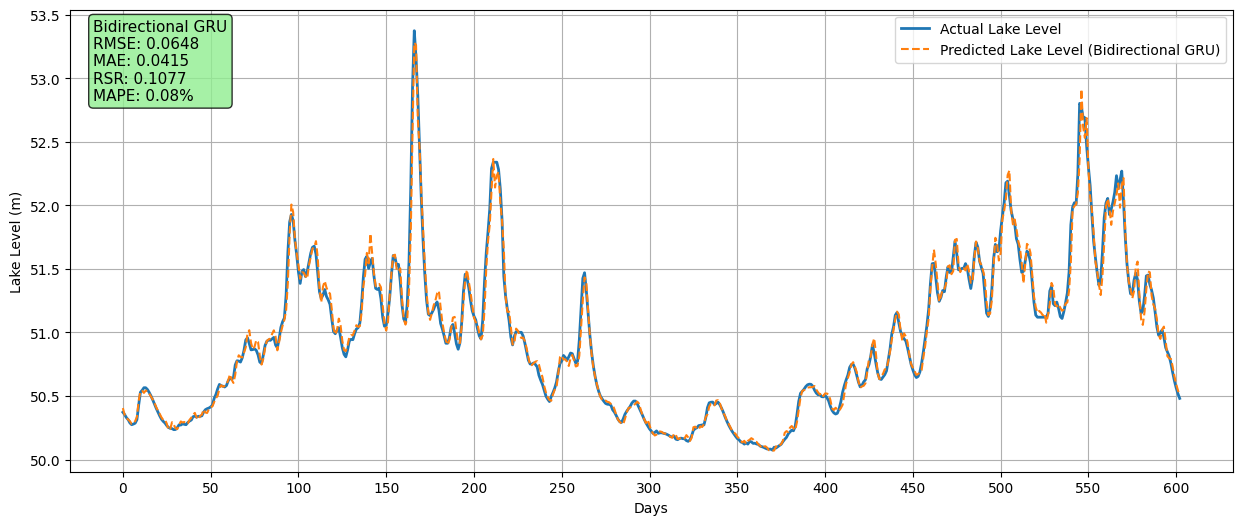

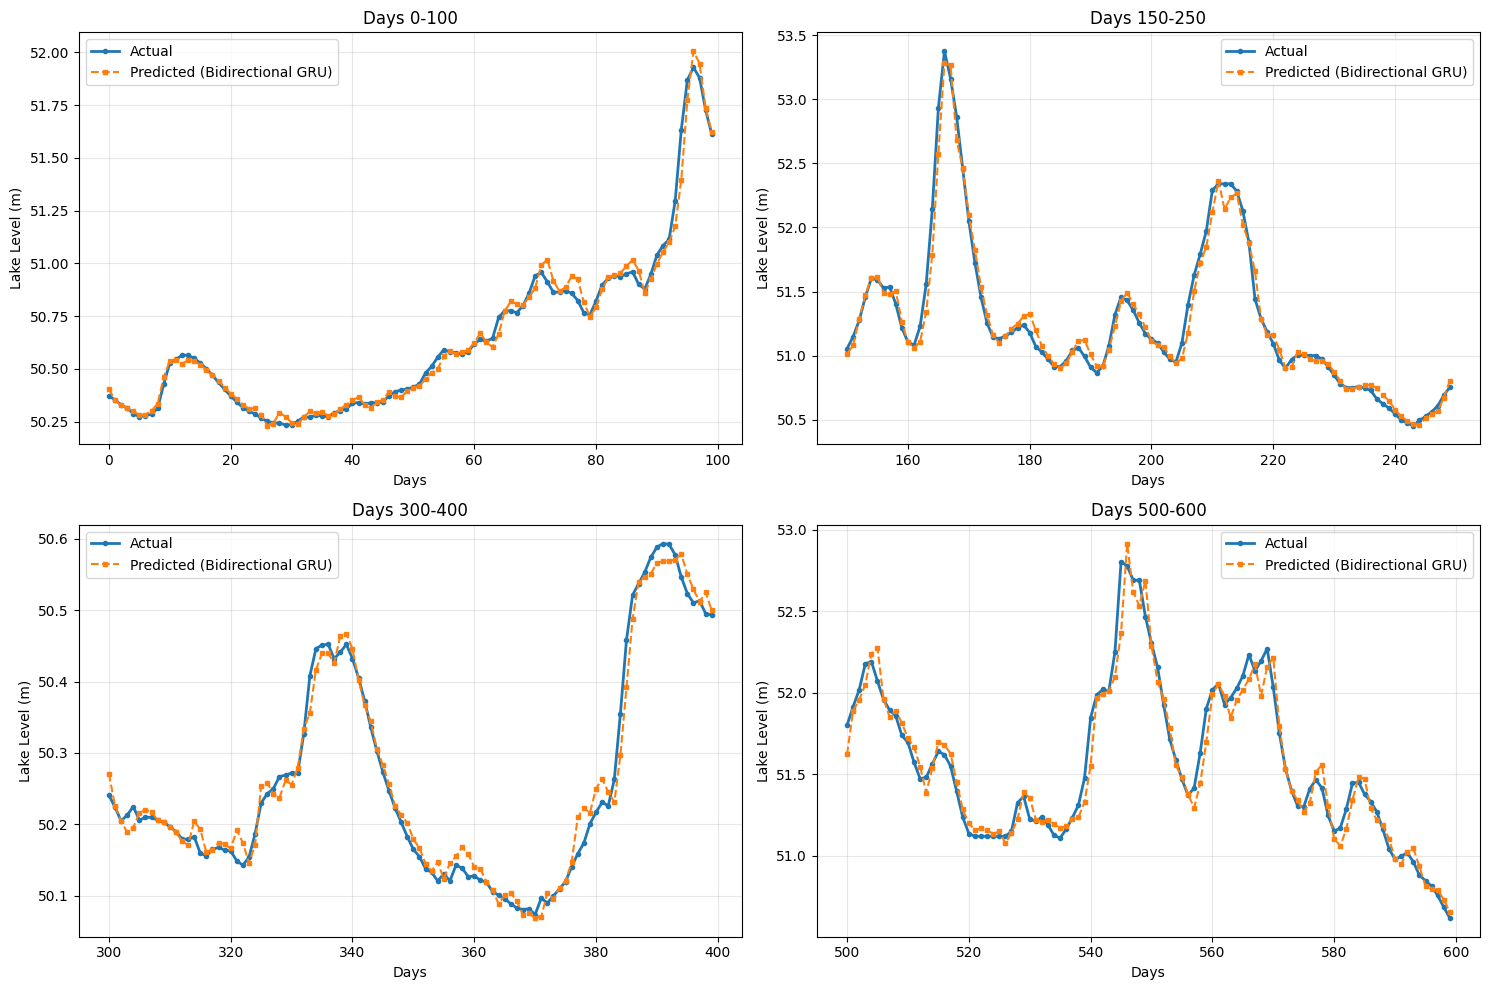

In [ ]:
#BIDIRECTIONAL GRU
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, Input, Bidirectional
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Load and preprocess data
df = pd.read_csv('DATOS.csv')

df['fecha'] = pd.to_datetime(df['fecha'], format='%d/%m/%Y')
df.set_index('fecha', inplace=True)

print("DataFrame head after setting date as index:")
print(df.head())
print("\nDataFrame info after setting date as index:")
df.info()

df.interpolate(method='linear', inplace=True)

print("DataFrame head after interpolation:")
print(df.head())
print("\nDataFrame info after interpolation:")
df.info()

# Initialize MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))

# Select all columns for scaling
features_to_scale = df.columns

# Apply scaling
df_scaled_array = scaler.fit_transform(df[features_to_scale])

# Convert the scaled array back to a DataFrame
df_scaled = pd.DataFrame(df_scaled_array, columns=features_to_scale, index=df.index)

print("First 5 rows of the scaled DataFrame (df_scaled):")
print(df_scaled.head())

print("\nDataFrame info after scaling:")
df_scaled.info()

# 1. Define the look_back period
look_back = 30

# 2. Define the index of the target column ('nivel_lago')
target_column_index = df_scaled.columns.get_loc('nivel_lago')

# 3. Implement a function to generate sequences
def create_sequences(data, look_back, target_index):
    X, y = [], []
    for i in range(look_back, len(data)):
        X.append(data.iloc[i-look_back : i].values) # Input features for the last 'look_back' days
        y.append(data.iloc[i, target_index])       # Target value for the current day
    return np.array(X), np.array(y)

# Generate sequences
X_data, y_data = create_sequences(df_scaled, look_back, target_column_index)

# 4. Split the arrays into training and test sets (80% train, 20% test chronologically)
train_size = int(len(X_data) * 0.8)

X_train, y_train = X_data[:train_size], y_data[:train_size]
X_test, y_test = X_data[train_size:], y_data[train_size:]

print(f"Shape of X_data: {X_data.shape}")
print(f"Shape of y_data: {y_data.shape}")
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

# Define the Bidirectional GRU model architecture
model = Sequential()

# Add an Input layer
model.add(Input(shape=(X_train.shape[1], X_train.shape[2])))

# First Bidirectional GRU layer
model.add(Bidirectional(GRU(units=128, return_sequences=True, recurrent_dropout=0.1)))
model.add(Dropout(0.3))

# Second Bidirectional GRU layer
model.add(Bidirectional(GRU(units=64, return_sequences=True, recurrent_dropout=0.1)))
model.add(Dropout(0.3))

# Third Bidirectional GRU layer (no return_sequences as it's the last GRU layer)
model.add(Bidirectional(GRU(units=32)))
model.add(Dropout(0.2))

# Output layer
model.add(Dense(units=1))

# Compile the model with optimized Adam optimizer
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae'])

# Print model summary
print(model.summary())

# Define callbacks for better training
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

# Train the model with callbacks
history = model.fit(
    X_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("Bidirectional GRU model training complete.")

# Plot training history
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# COMBINED GRAPH WITH METRICS
# Make predictions with the trained model
y_pred_scaled = model.predict(X_test)

# Reshape y_test for inverse transformation
y_test_reshaped = y_test.reshape(-1, 1)

# Create dummy arrays for inverse transformation
dummy_y_pred = np.zeros((len(y_pred_scaled), df_scaled.shape[1]))
dummy_y_test = np.zeros((len(y_test_reshaped), df_scaled.shape[1]))

# Place the scaled predictions and actual values into the correct column
dummy_y_pred[:, target_column_index] = y_pred_scaled[:, 0]
dummy_y_test[:, target_column_index] = y_test_reshaped[:, 0]

# Inverse transform the predictions and actual values to their original scale
y_pred = scaler.inverse_transform(dummy_y_pred)[:, target_column_index]
y_test_actual = scaler.inverse_transform(dummy_y_test)[:, target_column_index]

print(f"Shape of original y_test: {y_test.shape}")
print(f"Shape of y_pred: {y_pred.shape}")
print(f"Shape of y_test_actual: {y_test_actual.shape}")

# Calculate MAPE
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Avoid division by zero
    non_zero_indices = y_true != 0
    return np.mean(np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])) * 100

# Calculate metrics
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred))
mae = mean_absolute_error(y_test_actual, y_pred)
std_dev_y_test_actual = np.std(y_test_actual)
rsr = rmse / std_dev_y_test_actual
mape = mean_absolute_percentage_error(y_test_actual, y_pred)

print(f'RMSE: {rmse:.4f}')
print(f'MAE: {mae:.4f}')
print(f'RSR: {rsr:.4f}')
print(f'MAPE: {mape:.2f}%')

# Save Bidirectional GRU results
bi_gru_results = {
    'RMSE': rmse,
    'MAE': mae,
    'RSR': rsr,
    'MAPE': mape
}
print(f"\nBidirectional GRU results saved: RMSE={rmse:.4f}, MAE={mae:.4f}, RSR={rsr:.4f}, MAPE={mape:.2f}%")

# Plotting the results
plt.figure(figsize=(15, 6))
plt.plot(y_test_actual, label='Actual Lake Level', linewidth=2)
plt.plot(y_pred, label='Predicted Lake Level (Bidirectional GRU)', linestyle='--')

plt.xlabel('Days')
plt.ylabel('Lake Level (m)')

# Set x-ticks to skip in groups of 50
max_x_value = len(y_test_actual)
plt.xticks(np.arange(0, max_x_value, 50))

# Add metrics box
metrics_text = f'Bidirectional GRU\nRMSE: {rmse:.4f}\nMAE: {mae:.4f}\nRSR: {rsr:.4f}\nMAPE: {mape:.2f}%'
plt.text(0.02, 0.98, metrics_text,
         transform=plt.gca().transAxes,
         fontsize=11,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.8))

plt.legend()
plt.grid(True)
plt.show()

# Create multiple zoomed sections
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Define different zoom ranges
zoom_ranges = [(0, 100), (150, 250), (300, 400), (500, 600)]

for idx, (start, end) in enumerate(zoom_ranges):
    ax = axes[idx // 2, idx % 2]

    ax.plot(range(start, end),
            y_test_actual[start:end],
            label='Actual',
            linewidth=2,
            marker='o',
            markersize=3)
    ax.plot(range(start, end),
            y_pred[start:end],
            label='Predicted (Bidirectional GRU)',
            linestyle='--',
            marker='s',
            markersize=3)

    ax.set_title(f'Days {start}-{end}')
    ax.set_xlabel('Days')
    ax.set_ylabel('Lake Level (m)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

DataFrame head after setting date as index:
            nivel_lago  caudal_salida  precipitacion  temperatura  \
fecha                                                               
2012-01-01      51.780          292.0       2.754378        4.142   
2012-01-02      51.733          285.0       2.264622        4.150   
2012-01-03      51.809          294.0       1.616913        4.317   
2012-01-04      52.010          328.0      13.679318        4.492   
2012-01-05      52.430          393.0       0.014222        4.817   

            evapotranspiracion  
fecha                           
2012-01-01               2.604  
2012-01-02               2.309  
2012-01-03               2.829  
2012-01-04               3.024  
2012-01-05               2.438  

DataFrame info after setting date as index:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3042 entries, 2012-01-01 to 2020-04-29
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------            

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_18                │ (None, 30, 256)        │       137,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_33 (Dropout)            │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_19                │ (None, 30, 128)        │       164,352 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_34 (Dropout)            │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_20                │ (None, 64)             │        41,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 342,849 (1.31 MB)

 Trainable params: 342,849 (1.31 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 36s 288ms/step - loss: 0.0115 - mae: 0.0756 - val_loss: 0.0070 - val_mae: 0.0528 - learning_rate: 0.0010
Epoch 2/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 21s 273ms/step - loss: 0.0040 - mae: 0.0425 - val_loss: 0.0040 - val_mae: 0.0426 - learning_rate: 0.0010
Epoch 3/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 20s 259ms/step - loss: 0.0034 - mae: 0.0388 - val_loss: 0.0028 - val_mae: 0.0329 - learning_rate: 0.0010
Epoch 4/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 19s 257ms/step - loss: 0.0029 - mae: 0.0368 - val_loss: 0.0023 - val_mae: 0.0295 - learning_rate: 0.0010
Epoch 5/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 20s 249ms/step - loss: 0.0024 - mae: 0.0328 - val_loss: 0.0031 - val_mae: 0.0358 - learning_rate: 0.0010
Epoch 6/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 22s 268ms/step - loss: 0.0019 - mae: 0.0302 - val_loss: 0.0015 - val_mae: 0.0252 - learning_rate: 0.0010
Epoch 7/150
76/76 ━━━━━━━━━━━━━━━━━━━━ 19s 256ms/step - loss: 0.0019 - mae: 0.0299 - val_loss: 0.0015 - val_mae: 0.0248 - learning_

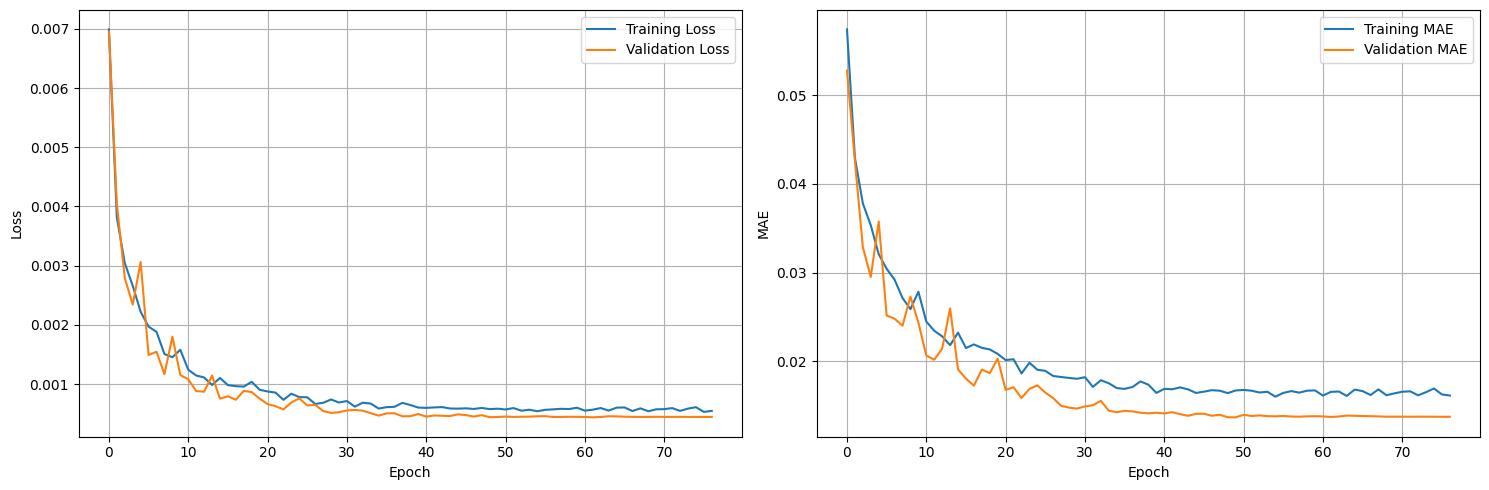

19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 280ms/step
Shape of original y_test: (603,)
Shape of y_pred: (603,)
Shape of y_test_actual: (603,)
RMSE: 0.0789
MAE: 0.0516
RSR: 0.1313
MAPE: 0.10%

Bidirectional LSTM results saved: RMSE=0.0789, MAE=0.0516, RSR=0.1313, MAPE=0.10%


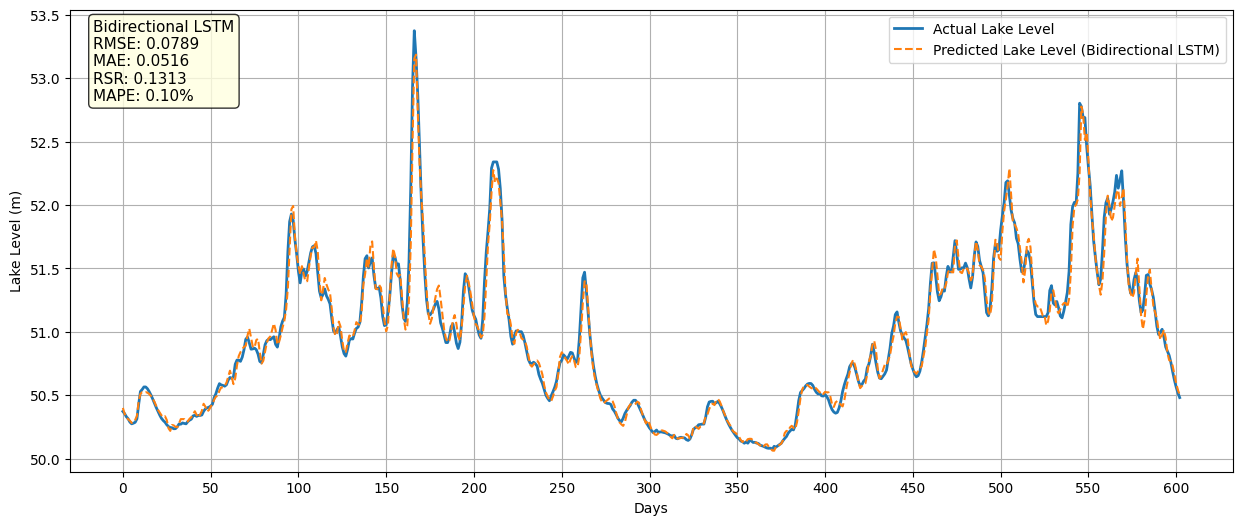

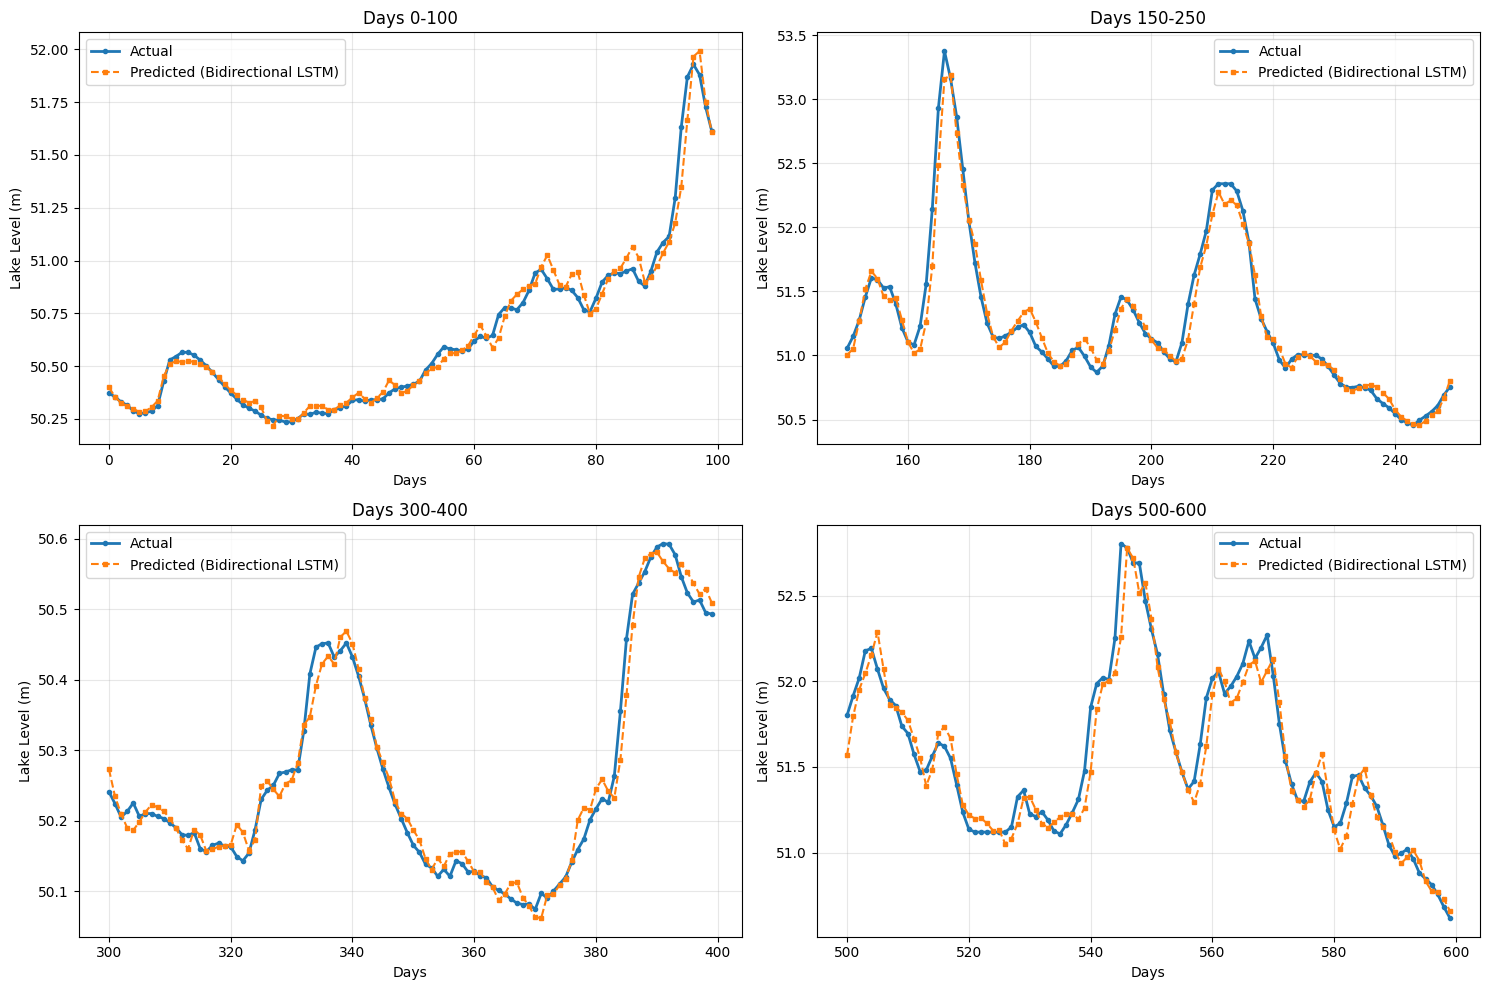

In [ ]:
#BIDIRECTIONAL LSTM
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input, Bidirectional
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Load and preprocess data
df = pd.read_csv('DATOS.csv')

df['fecha'] = pd.to_datetime(df['fecha'], format='%d/%m/%Y')
df.set_index('fecha', inplace=True)

print("DataFrame head after setting date as index:")
print(df.head())
print("\nDataFrame info after setting date as index:")
df.info()

df.interpolate(method='linear', inplace=True)

print("DataFrame head after interpolation:")
print(df.head())
print("\nDataFrame info after interpolation:")
df.info()

# Initialize MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))

# Select all columns for scaling
features_to_scale = df.columns

# Apply scaling
df_scaled_array = scaler.fit_transform(df[features_to_scale])

# Convert the scaled array back to a DataFrame
df_scaled = pd.DataFrame(df_scaled_array, columns=features_to_scale, index=df.index)

print("First 5 rows of the scaled DataFrame (df_scaled):")
print(df_scaled.head())

print("\nDataFrame info after scaling:")
df_scaled.info()

# 1. Define the look_back period
look_back = 30

# 2. Define the index of the target column ('nivel_lago')
target_column_index = df_scaled.columns.get_loc('nivel_lago')

# 3. Implement a function to generate sequences
def create_sequences(data, look_back, target_index):
    X, y = [], []
    for i in range(look_back, len(data)):
        X.append(data.iloc[i-look_back : i].values) # Input features for the last 'look_back' days
        y.append(data.iloc[i, target_index])       # Target value for the current day
    return np.array(X), np.array(y)

# Generate sequences
X_data, y_data = create_sequences(df_scaled, look_back, target_column_index)

# 4. Split the arrays into training and test sets (80% train, 20% test chronologically)
train_size = int(len(X_data) * 0.8)

X_train, y_train = X_data[:train_size], y_data[:train_size]
X_test, y_test = X_data[train_size:], y_data[train_size:]

print(f"Shape of X_data: {X_data.shape}")
print(f"Shape of y_data: {y_data.shape}")
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

# Define the Bidirectional LSTM model architecture
model = Sequential()

# Add an Input layer
model.add(Input(shape=(X_train.shape[1], X_train.shape[2])))

# First Bidirectional LSTM layer
model.add(Bidirectional(LSTM(units=128, return_sequences=True, recurrent_dropout=0.1)))
model.add(Dropout(0.3))

# Second Bidirectional LSTM layer
model.add(Bidirectional(LSTM(units=64, return_sequences=True, recurrent_dropout=0.1)))
model.add(Dropout(0.3))

# Third Bidirectional LSTM layer (no return_sequences as it's the last LSTM layer)
model.add(Bidirectional(LSTM(units=32)))
model.add(Dropout(0.2))

# Output layer
model.add(Dense(units=1))

# Compile the model with optimized Adam optimizer
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae'])

# Print model summary
print(model.summary())

# Define callbacks for better training
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

# Train the model with callbacks
history = model.fit(
    X_train, y_train,
    epochs=150,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("Bidirectional LSTM model training complete.")

# Plot training history
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# COMBINED GRAPH WITH METRICS
# Make predictions with the trained model
y_pred_scaled = model.predict(X_test)

# Reshape y_test for inverse transformation
y_test_reshaped = y_test.reshape(-1, 1)

# Create dummy arrays for inverse transformation
dummy_y_pred = np.zeros((len(y_pred_scaled), df_scaled.shape[1]))
dummy_y_test = np.zeros((len(y_test_reshaped), df_scaled.shape[1]))

# Place the scaled predictions and actual values into the correct column
dummy_y_pred[:, target_column_index] = y_pred_scaled[:, 0]
dummy_y_test[:, target_column_index] = y_test_reshaped[:, 0]

# Inverse transform the predictions and actual values to their original scale
y_pred = scaler.inverse_transform(dummy_y_pred)[:, target_column_index]
y_test_actual = scaler.inverse_transform(dummy_y_test)[:, target_column_index]

print(f"Shape of original y_test: {y_test.shape}")
print(f"Shape of y_pred: {y_pred.shape}")
print(f"Shape of y_test_actual: {y_test_actual.shape}")

# Calculate MAPE
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Avoid division by zero
    non_zero_indices = y_true != 0
    return np.mean(np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])) * 100

# Calculate metrics
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred))
mae = mean_absolute_error(y_test_actual, y_pred)
std_dev_y_test_actual = np.std(y_test_actual)
rsr = rmse / std_dev_y_test_actual
mape = mean_absolute_percentage_error(y_test_actual, y_pred)

print(f'RMSE: {rmse:.4f}')
print(f'MAE: {mae:.4f}')
print(f'RSR: {rsr:.4f}')
print(f'MAPE: {mape:.2f}%')

# Save Bidirectional LSTM results
bi_lstm_results = {
    'RMSE': rmse,
    'MAE': mae,
    'RSR': rsr,
    'MAPE': mape
}
print(f"\nBidirectional LSTM results saved: RMSE={rmse:.4f}, MAE={mae:.4f}, RSR={rsr:.4f}, MAPE={mape:.2f}%")

# Plotting the results
plt.figure(figsize=(15, 6))
plt.plot(y_test_actual, label='Actual Lake Level', linewidth=2)
plt.plot(y_pred, label='Predicted Lake Level (Bidirectional LSTM)', linestyle='--')

plt.xlabel('Days')
plt.ylabel('Lake Level (m)')

# Set x-ticks to skip in groups of 50
max_x_value = len(y_test_actual)
plt.xticks(np.arange(0, max_x_value, 50))

# Add metrics box
metrics_text = f'Bidirectional LSTM\nRMSE: {rmse:.4f}\nMAE: {mae:.4f}\nRSR: {rsr:.4f}\nMAPE: {mape:.2f}%'
plt.text(0.02, 0.98, metrics_text,
         transform=plt.gca().transAxes,
         fontsize=11,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.legend()
plt.grid(True)
plt.show()

# Create multiple zoomed sections
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Define different zoom ranges
zoom_ranges = [(0, 100), (150, 250), (300, 400), (500, 600)]

for idx, (start, end) in enumerate(zoom_ranges):
    ax = axes[idx // 2, idx % 2]

    ax.plot(range(start, end),
            y_test_actual[start:end],
            label='Actual',
            linewidth=2,
            marker='o',
            markersize=3)
    ax.plot(range(start, end),
            y_pred[start:end],
            label='Predicted (Bidirectional LSTM)',
            linestyle='--',
            marker='s',
            markersize=3)

    ax.set_title(f'Days {start}-{end}')
    ax.set_xlabel('Days')
    ax.set_ylabel('Lake Level (m)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

DataFrame head after setting date as index:
            nivel_lago  caudal_salida  precipitacion  temperatura  \
fecha                                                               
2012-01-01      51.780          292.0       2.754378        4.142   
2012-01-02      51.733          285.0       2.264622        4.150   
2012-01-03      51.809          294.0       1.616913        4.317   
2012-01-04      52.010          328.0      13.679318        4.492   
2012-01-05      52.430          393.0       0.014222        4.817   

            evapotranspiracion  
fecha                           
2012-01-01               2.604  
2012-01-02               2.309  
2012-01-03               2.829  
2012-01-04               3.024  
2012-01-05               2.438  

DataFrame info after setting date as index:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3042 entries, 2012-01-01 to 2020-04-29
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------            

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_15 (LSTM)                  │ (None, 30, 128)        │        68,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_16 (LSTM)                  │ (None, 30, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_17 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,465 (509.63 KB)

 Trainable params: 130,465 (509.63 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 18s 152ms/step - loss: 0.0108 - mae: 0.0753 - val_loss: 0.0075 - val_mae: 0.0535 - learning_rate: 0.0010
Epoch 2/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 11s 145ms/step - loss: 0.0055 - mae: 0.0516 - val_loss: 0.0060 - val_mae: 0.0482 - learning_rate: 0.0010
Epoch 3/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 19s 127ms/step - loss: 0.0051 - mae: 0.0496 - val_loss: 0.0048 - val_mae: 0.0444 - learning_rate: 0.0010
Epoch 4/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 8s 111ms/step - loss: 0.0040 - mae: 0.0432 - val_loss: 0.0040 - val_mae: 0.0395 - learning_rate: 0.0010
Epoch 5/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 11s 116ms/step - loss: 0.0032 - mae: 0.0395 - val_loss: 0.0031 - val_mae: 0.0356 - learning_rate: 0.0010
Epoch 6/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 10s 125ms/step - loss: 0.0039 - mae: 0.0422 - val_loss: 0.0028 - val_mae: 0.0381 - learning_rate: 0.0010
Epoch 7/100
76/76 ━━━━━━━━━━━━━━━━━━━━ 10s 128ms/step - loss: 0.0027 - mae: 0.0353 - val_loss: 0.0019 - val_mae: 0.0287 - learning_r

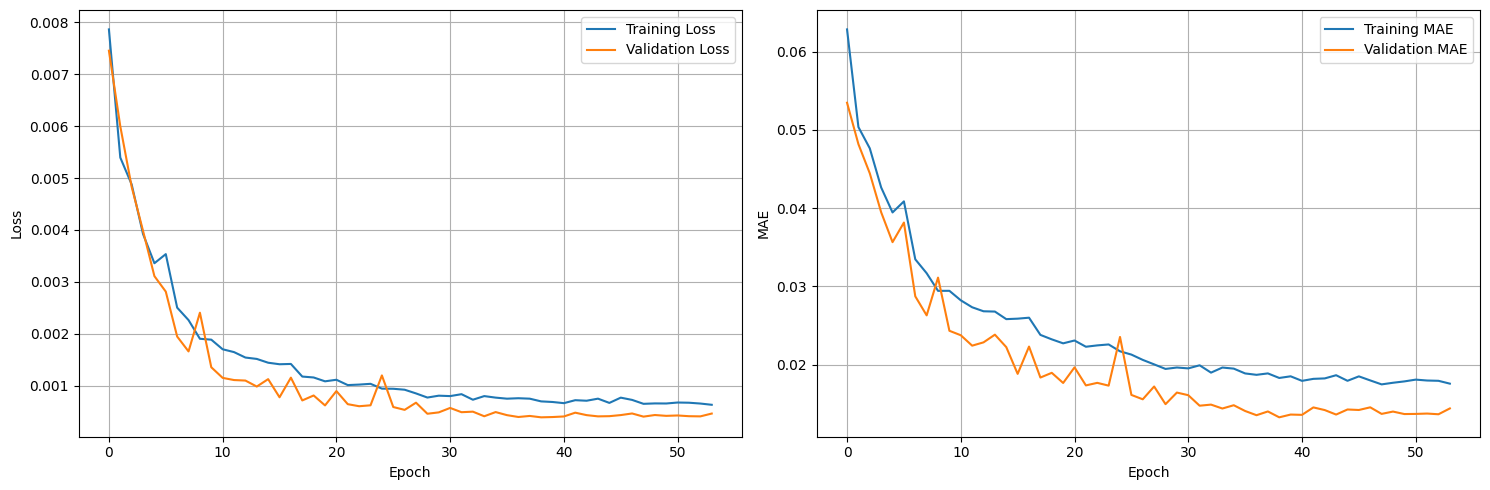

19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step
Shape of original y_test: (603,)
Shape of y_pred: (603,)
Shape of y_test_actual: (603,)
RMSE: 0.0742
MAE: 0.0499
RSR: 0.1234
MAPE: 0.10%

Simple LSTM results saved: RMSE=0.0742, MAE=0.0499, RSR=0.1234, MAPE=0.10%


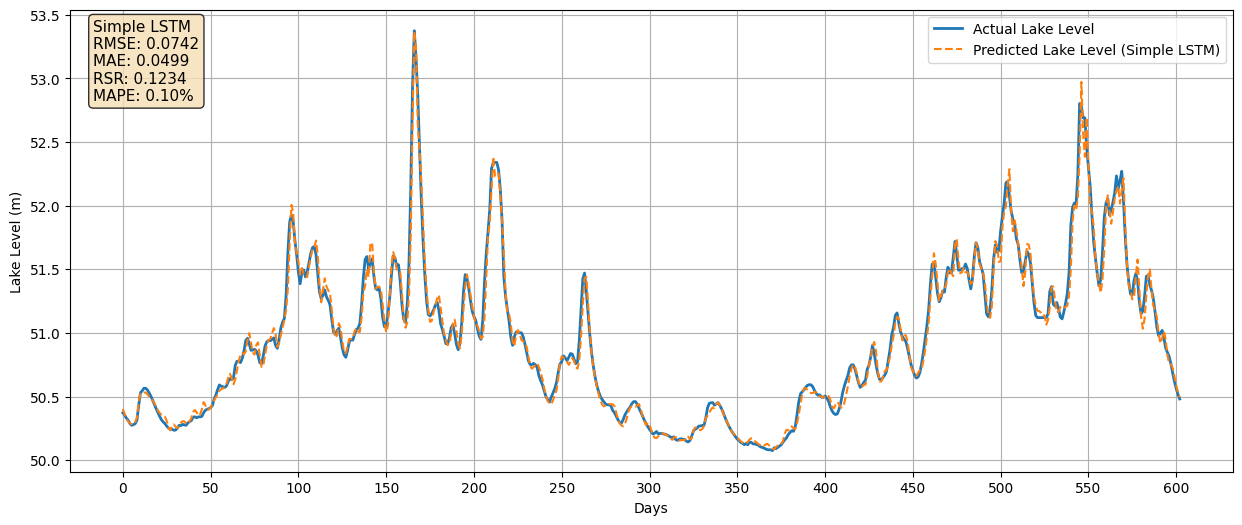

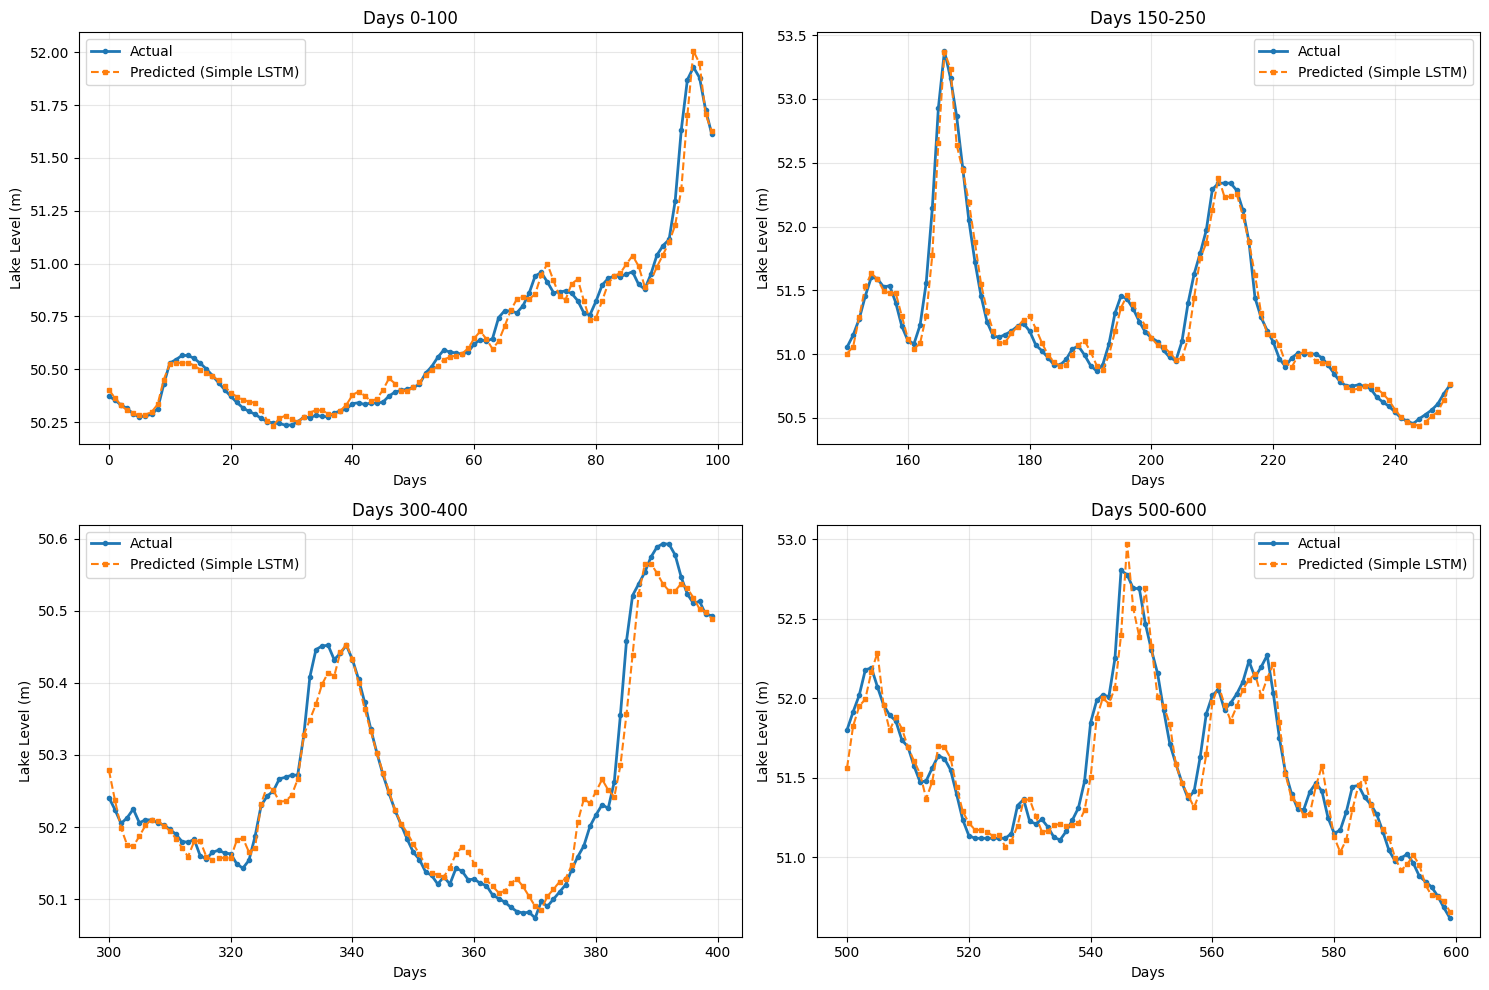

In [ ]:
#SIMPLE LSTM MODEL
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Load and preprocess data
df = pd.read_csv('DATOS.csv')

df['fecha'] = pd.to_datetime(df['fecha'], format='%d/%m/%Y')
df.set_index('fecha', inplace=True)

print("DataFrame head after setting date as index:")
print(df.head())
print("\nDataFrame info after setting date as index:")
df.info()

df.interpolate(method='linear', inplace=True)

print("DataFrame head after interpolation:")
print(df.head())
print("\nDataFrame info after interpolation:")
df.info()

# Initialize MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))

# Select all columns for scaling
features_to_scale = df.columns

# Apply scaling
df_scaled_array = scaler.fit_transform(df[features_to_scale])

# Convert the scaled array back to a DataFrame
df_scaled = pd.DataFrame(df_scaled_array, columns=features_to_scale, index=df.index)

print("First 5 rows of the scaled DataFrame (df_scaled):")
print(df_scaled.head())

print("\nDataFrame info after scaling:")
df_scaled.info()

# 1. Define the look_back period
look_back = 30

# 2. Define the index of the target column ('nivel_lago')
target_column_index = df_scaled.columns.get_loc('nivel_lago')

# 3. Implement a function to generate sequences
def create_sequences(data, look_back, target_index):
    X, y = [], []
    for i in range(look_back, len(data)):
        X.append(data.iloc[i-look_back : i].values) # Input features for the last 'look_back' days
        y.append(data.iloc[i, target_index])       # Target value for the current day
    return np.array(X), np.array(y)

# Generate sequences
X_data, y_data = create_sequences(df_scaled, look_back, target_column_index)

# 4. Split the arrays into training and test sets (80% train, 20% test chronologically)
train_size = int(len(X_data) * 0.8)

X_train, y_train = X_data[:train_size], y_data[:train_size]
X_test, y_test = X_data[train_size:], y_data[train_size:]

print(f"Shape of X_data: {X_data.shape}")
print(f"Shape of y_data: {y_data.shape}")
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

# Define the simple LSTM model architecture
model = Sequential()

# Add an Input layer
model.add(Input(shape=(X_train.shape[1], X_train.shape[2])))

# First LSTM layer
model.add(LSTM(units=128, return_sequences=True, recurrent_dropout=0.1))
model.add(Dropout(0.3))

# Second LSTM layer
model.add(LSTM(units=64, return_sequences=True, recurrent_dropout=0.1))
model.add(Dropout(0.3))

# Third LSTM layer (no return_sequences as it's the last LSTM layer)
model.add(LSTM(units=32))
model.add(Dropout(0.2))

# Output layer
model.add(Dense(units=1))

# Compile the model with optimized Adam optimizer
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mae'])

# Print model summary
print(model.summary())

# Define callbacks for better training
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

# Train the model with callbacks
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("Simple LSTM model training complete.")

# Plot training history
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# COMBINED GRAPH WITH METRICS
# Make predictions with the trained model
y_pred_scaled = model.predict(X_test)

# Reshape y_test for inverse transformation
y_test_reshaped = y_test.reshape(-1, 1)

# Create dummy arrays for inverse transformation
dummy_y_pred = np.zeros((len(y_pred_scaled), df_scaled.shape[1]))
dummy_y_test = np.zeros((len(y_test_reshaped), df_scaled.shape[1]))

# Place the scaled predictions and actual values into the correct column
dummy_y_pred[:, target_column_index] = y_pred_scaled[:, 0]
dummy_y_test[:, target_column_index] = y_test_reshaped[:, 0]

# Inverse transform the predictions and actual values to their original scale
y_pred = scaler.inverse_transform(dummy_y_pred)[:, target_column_index]
y_test_actual = scaler.inverse_transform(dummy_y_test)[:, target_column_index]

print(f"Shape of original y_test: {y_test.shape}")
print(f"Shape of y_pred: {y_pred.shape}")
print(f"Shape of y_test_actual: {y_test_actual.shape}")

# Calculate MAPE
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Avoid division by zero
    non_zero_indices = y_true != 0
    return np.mean(np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])) * 100

# Calculate metrics
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred))
mae = mean_absolute_error(y_test_actual, y_pred)
std_dev_y_test_actual = np.std(y_test_actual)
rsr = rmse / std_dev_y_test_actual
mape = mean_absolute_percentage_error(y_test_actual, y_pred)

print(f'RMSE: {rmse:.4f}')
print(f'MAE: {mae:.4f}')
print(f'RSR: {rsr:.4f}')
print(f'MAPE: {mape:.2f}%')

simple_lstm_results = {
    'RMSE': rmse,
    'MAE': mae,
    'RSR': rsr,
    'MAPE': mape
}
print(f"\nSimple LSTM results saved: RMSE={rmse:.4f}, MAE={mae:.4f}, RSR={rsr:.4f}, MAPE={mape:.2f}%")

# Plotting the results
plt.figure(figsize=(15, 6))
plt.plot(y_test_actual, label='Actual Lake Level', linewidth=2)
plt.plot(y_pred, label='Predicted Lake Level (Simple LSTM)', linestyle='--')

plt.xlabel('Days')
plt.ylabel('Lake Level (m)')

# Set x-ticks to skip in groups of 50
max_x_value = len(y_test_actual)
plt.xticks(np.arange(0, max_x_value, 50))

# Add metrics box
metrics_text = f'Simple LSTM\nRMSE: {rmse:.4f}\nMAE: {mae:.4f}\nRSR: {rsr:.4f}\nMAPE: {mape:.2f}%'
plt.text(0.02, 0.98, metrics_text,
         transform=plt.gca().transAxes,
         fontsize=11,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.legend()
plt.grid(True)
plt.show()

# Create multiple zoomed sections
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Define different zoom ranges
zoom_ranges = [(0, 100), (150, 250), (300, 400), (500, 600)]

for idx, (start, end) in enumerate(zoom_ranges):
    ax = axes[idx // 2, idx % 2]

    ax.plot(range(start, end),
            y_test_actual[start:end],
            label='Actual',
            linewidth=2,
            marker='o',
            markersize=3)
    ax.plot(range(start, end),
            y_pred[start:end],
            label='Predicted (Simple LSTM)',
            linestyle='--',
            marker='s',
            markersize=3)

    ax.set_title(f'Days {start}-{end}')
    ax.set_xlabel('Days')
    ax.set_ylabel('Lake Level (m)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

                         MODEL PERFORMANCE COMPARISON


,RMSE,MAE,RSR,MAPE
Model,,,,
Simple GRU,0.063452,0.040075,0.105524,0.078052
Simple LSTM,0.074175,0.049861,0.123356,0.097222
Bidirectional GRU,0.064902,0.041788,0.107934,0.081430
Bidirectional LSTM,0.078944,0.051560,0.131287,0.100483



BEST PERFORMING MODELS (Lower is Better)
RMSE  : Simple GRU           = 0.063452
MAE   : Simple GRU           = 0.040075
RSR   : Simple GRU           = 0.105524
MAPE  : Simple GRU           = 0.078052%


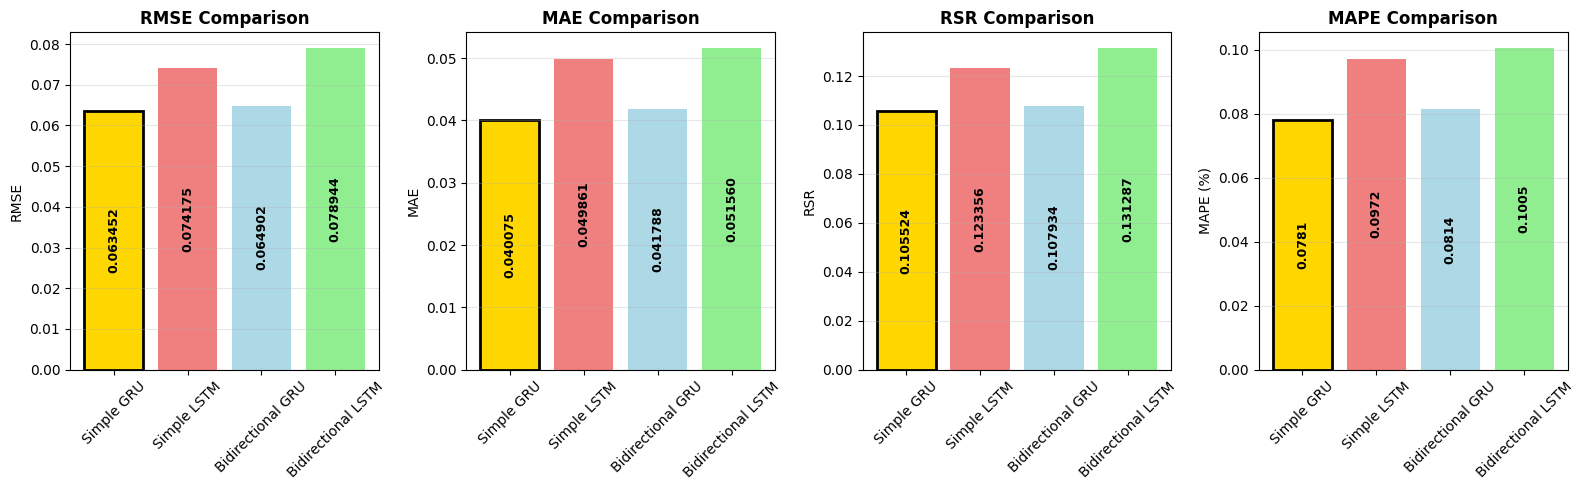

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Create comparison table from saved results
all_model_results = {
    'Simple GRU': simple_gru_results,
    'Simple LSTM': simple_lstm_results,
    'Bidirectional GRU': bi_gru_results,
    'Bidirectional LSTM': bi_lstm_results
}

comparison_df = pd.DataFrame(all_model_results).T
comparison_df.index.name = 'Model'

# Display styled table with color gradient (Red = bad, Green = good)
styled_table = comparison_df.style.background_gradient(
    cmap='RdYlGn_r',  # Red-Yellow-Green reversed (lower is better)
    axis=0  # Apply gradient column-wise
).format({
    'RMSE': '{:.6f}',
    'MAE': '{:.6f}',
    'RSR': '{:.6f}',
    'MAPE': '{:.6f}'
})

print("="*80)
print(" " * 25 + "MODEL PERFORMANCE COMPARISON")
print("="*80)
display(styled_table)

# Summary of best models
print("\n" + "="*80)
print("BEST PERFORMING MODELS (Lower is Better)")
print("="*80)
for metric in comparison_df.columns:
    best_model = comparison_df[metric].idxmin()
    best_value = comparison_df[metric].min()
    unit = '%' if metric == 'MAPE' else ''
    print(f"{metric:6s}: {best_model:20s} = {best_value:.6f}{unit}")
print("="*80)

# Create visual comparison with values inside bars
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
metrics = ['RMSE', 'MAE', 'RSR', 'MAPE']
colors = ['wheat', 'lightcoral', 'lightblue', 'lightgreen']

for idx, metric in enumerate(metrics):
    ax = axes[idx]
    values = comparison_df[metric].values
    models = comparison_df.index.values

    bars = ax.bar(models, values, color=colors)
    ax.set_title(f'{metric} Comparison', fontsize=12, fontweight='bold')
    ax.set_ylabel(metric if metric != 'MAPE' else 'MAPE (%)')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3, axis='y')

    # Highlight the best (lowest) value
    best_idx = values.argmin()
    bars[best_idx].set_color('gold')
    bars[best_idx].set_edgecolor('black')
    bars[best_idx].set_linewidth(2)

    # Add value labels inside bars
    for i, (bar, value) in enumerate(zip(bars, values)):
        height = bar.get_height()
        # Format based on metric
        if metric == 'MAPE':
            label = f'{value:.4f}'
        else:
            label = f'{value:.6f}'

        ax.text(bar.get_x() + bar.get_width()/2., height/2.,
                label,
                ha='center', va='center',
                fontsize=9, fontweight='bold',
                rotation=90, color='black')

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Create output folder
output_folder = 'exported_plots'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# Turn off display to save figures without showing
plt.ioff()

# 1. Simple GRU Prediction
fig = plt.figure(figsize=(15, 6))
plt.plot(y_test_actual, label='Actual Lake Level', linewidth=2)
plt.plot(y_pred_simple_gru, label='Predicted Lake Level (Simple GRU)', linestyle='--')
plt.xlabel('Days')
plt.ylabel('Lake Level (m)')
plt.xticks(np.arange(0, len(y_test_actual), 50))
plt.legend()
plt.grid(True)
plt.savefig(f'{output_folder}/simple_gru_prediction.png', dpi=300, bbox_inches='tight')
plt.close()

# 2. Comparison Bar Charts
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
metrics = ['RMSE', 'MAE', 'RSR', 'MAPE']
colors = ['wheat', 'lightcoral', 'lightblue', 'lightgreen']
for idx, metric in enumerate(metrics):
    ax = axes[idx]
    values = comparison_df[metric].values
    models = comparison_df.index.values
    bars = ax.bar(models, values, color=colors)
    ax.set_title(f'{metric} Comparison', fontsize=12, fontweight='bold')
    # ... rest of your plotting code ...
plt.savefig(f'{output_folder}/metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.close()

# Repeat for other plots...

plt.ion()  # Turn interactive mode back on
print("All figures exported!")

NameError: name 'y_test_actual' is not defined

In [ ]:
# Check which figures you have
import matplotlib.pyplot as plt

fig_nums = plt.get_fignums()
print(f"You have {len(fig_nums)} figures:")
for num in fig_nums:
    fig = plt.figure(num)
    title = fig.axes[0].get_title() if fig.axes and fig.axes[0].get_title() else "No title"
    print(f"  Figure {num}: {title}")

You have 0 figures:


In [ ]:
import matplotlib.pyplot as plt
import os

# Create a folder for exported images (optional but recommended)
output_folder = 'exported_plots'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
    print(f"Created folder: {output_folder}")

# Dictionary to map figure numbers to descriptive names
# Update these numbers based on the order your figures were created
figure_names = {
    1: 'simple_gru_training_history',
    2: 'simple_gru_prediction',
    3: 'simple_gru_zoomed_sections',
    4: 'simple_lstm_training_history',
    5: 'simple_lstm_prediction',
    6: 'simple_lstm_zoomed_sections',
    7: 'bidirectional_gru_training_history',
    8: 'bidirectional_gru_prediction',
    9: 'bidirectional_gru_zoomed_sections',
    10: 'bidirectional_lstm_training_history',
    11: 'bidirectional_lstm_prediction',
    12: 'bidirectional_lstm_zoomed_sections',
    13: 'all_models_comparison',
    14: 'metrics_comparison_bar_charts'
}

# Get all figure numbers currently in memory
fig_nums = plt.get_fignums()

print(f"Found {len(fig_nums)} figures to export")
print("-" * 60)

# Save each figure
saved_count = 0
for num in fig_nums:
    fig = plt.figure(num)

    # Use descriptive name if available, otherwise use generic name
    if num in figure_names:
        filename = figure_names[num]
    else:
        filename = f'figure_{num}'

    # Save with full path
    filepath = os.path.join(output_folder, f'{filename}.png')
    fig.savefig(filepath, dpi=300, bbox_inches='tight', facecolor='white')

    print(f"✓ Saved: {filename}.png")
    saved_count += 1

print("-" * 60)
print(f"Successfully saved {saved_count} figures to '{output_folder}/' folder")

# Optional: Also save as PDF for publication quality
save_pdf = input("\nDo you want to save as PDF too? (y/n): ").lower()
if save_pdf == 'y':
    for num in fig_nums:
        fig = plt.figure(num)
        if num in figure_names:
            filename = figure_names[num]
        else:
            filename = f'figure_{num}'
        filepath = os.path.join(output_folder, f'{filename}.pdf')
        fig.savefig(filepath, bbox_inches='tight', facecolor='white')
    print(f"✓ Also saved {saved_count} figures as PDF")

Created folder: exported_plots
Found 0 figures to export
------------------------------------------------------------
------------------------------------------------------------
Successfully saved 0 figures to 'exported_plots/' folder

Do you want to save as PDF too? (y/n): n
